# Visualizing Simulation Results 
This code was used to create Figures 6 and 7 in the manuscript

In [1]:
import sys
sys.path.append('../../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp

# Idealized BC

In [2]:
input_folder = '../../output/idealized/'

In [ ]:
constant_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "imp10": "imp10.pkl",
    "imp50": "imp50.pkl",
    "cap": "cap.pkl",
}

constant_dbs = {}
for parametrization, filename in constant_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        constant_dbs[parametrization] = pickle.load(pickle_file)


### Overview over ice content in domain

In [4]:
for idx,parametrization in enumerate(constant_dbs):
    print("================================")
    print(parametrization)
    theta_i_total = constant_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    av_max = 0
    nz, nx = jnp.shape(theta_i_total[0])
    for i in range(len(theta_i_total)):
        av_max_i = jnp.sum(theta_i_total[i][nz//2:,:])/(nz//2*nx)
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
        if av_max_i>av_max:
            av_max = av_max_i
            id_av_max = i
    print("================================")
    print("Maximum theta_i:", jnp.round(id_max/12), max_theta_i)
    print("Average maximum:", jnp.round(id_av_max/12), av_max)
    print("Final time step, average:", i/12, av_max_i)
    print("Final time step, maximum:", i/12, jnp.max(theta_i_total[-1]),"\n")
    

drying
Maximum theta_i: 58.0 0.17940602
Average maximum: 80.0 0.08559148
Final time step, average: 130.0 1.4092044e-15
Final time step, maximum: 130.0 0.03343062 

drying_omega10
Maximum theta_i: 78.0 0.16261245
Average maximum: 78.0 0.0740054
Final time step, average: 130.0 1.122255e-15
Final time step, maximum: 130.0 0.02348026 

permaFoam_omega10
Maximum theta_i: 80.0 0.16358313
Average maximum: 79.0 0.08503528
Final time step, average: 130.0 1.4177097e-15
Final time step, maximum: 130.0 0.04211011 

permaFoam_omega50
Maximum theta_i: 78.0 0.15788049
Average maximum: 81.0 0.061467506
Final time step, average: 130.0 1.1772944e-15
Final time step, maximum: 130.0 0.016033348 

cap
Maximum theta_i: 70.0 0.29246128
Average maximum: 90.0 0.10020257
Final time step, average: 130.0 0.02202599
Final time step, maximum: 130.0 0.18150547 



### Create Figure 6

/home/anne/anaconda3/envs/cryorich_AD/lib/python3.12/site-packages/matplotlib/patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


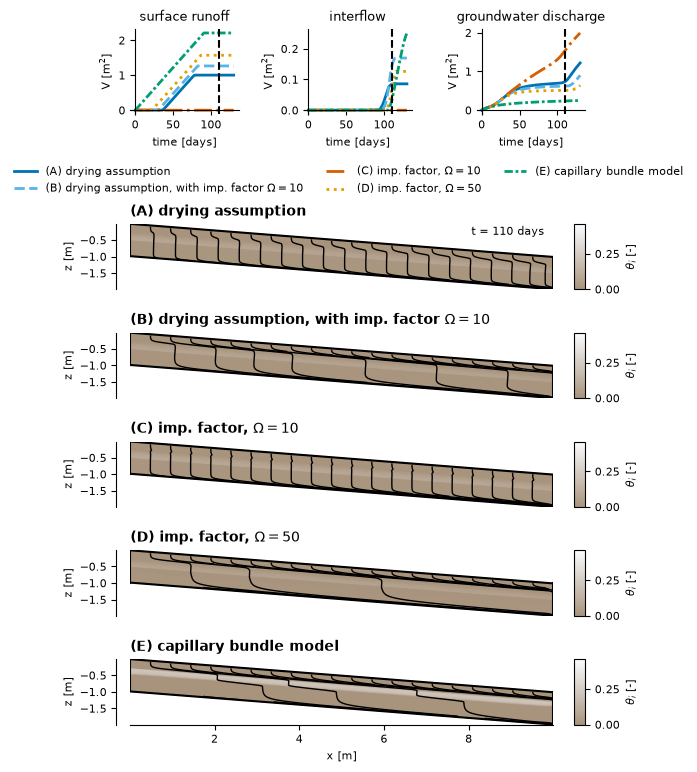

In [5]:
index = 12*110
cm = 1/2.54  # centimeters in inches
fig, axes = plotting_utils.plot_streamlines_grid(constant_dbs, index, slope=-0.1,figsize=(15*cm,19.41*cm),cum=True)
fig.savefig(f"../../figures/results/idealized/idealized_{index//12}d_streamlines_cum.png", dpi=600, bbox_inches="tight")

### Temperature distribution     

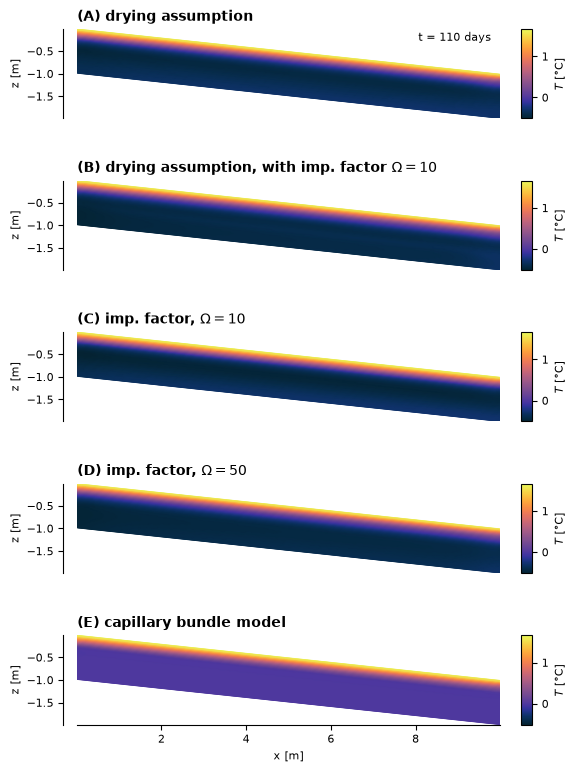

In [6]:
fig, axes = plotting_utils.plot_T_grid(constant_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../../figures/results/idealized/idealized_{index//12}d_T.png", dpi=600, bbox_inches="tight")

# ERA5-Land BC Simulation

In [8]:
input_folder = '../../output/simulation/simulation_'


In [ ]:
era5_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "imp10": "imp10.pkl",
    "imp50": "imp50.pkl",
    "cap": "cap.pkl",
}

era5_dbs = {}
for parametrization, filename in era5_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        era5_dbs[parametrization] = pickle.load(pickle_file)


### Overview over ice content in domain

In [10]:
for idx,parametrization in enumerate(era5_dbs):
    print("================================")
    print(parametrization)
    theta_i_total = era5_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    av_max = 0
    nz, nx = jnp.shape(theta_i_total[0])
    for i in range(len(theta_i_total)):
        av_max_i = jnp.sum(theta_i_total[i][nz//2:,:])/(nz//2*nx)
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
        if av_max_i>av_max:
            av_max = av_max_i
            id_av_max = i
    print("================================")
    print("Maximum theta_i:", jnp.round(id_max/12), max_theta_i)
    print("Average maximum:", jnp.round(id_av_max/12), av_max)
    print("Final time step, average:", i/12, av_max_i)
    print("Final time step, maximum:", i/12, jnp.max(theta_i_total[-1]),"\n")

drying
Maximum theta_i: 15.0 0.23579916
Average maximum: 15.0 0.17070878
Final time step, average: 17.666666666666668 4.3019944e-15
Final time step, maximum: 17.666666666666668 2.9112147e-05 

drying_omega10
Maximum theta_i: 14.0 0.19656707
Average maximum: 16.0 0.1228685
Final time step, average: 17.666666666666668 4.440077e-15
Final time step, maximum: 17.666666666666668 2.9112147e-05 

permaFoam_omega10
Maximum theta_i: 14.0 0.20665736
Average maximum: 15.0 0.15056552
Final time step, average: 17.666666666666668 4.425427e-15
Final time step, maximum: 17.666666666666668 2.9112147e-05 

permaFoam_omega50
Maximum theta_i: 15.0 0.19068082
Average maximum: 15.0 0.084199935
Final time step, average: 17.666666666666668 4.6819805e-15
Final time step, maximum: 17.666666666666668 2.9112147e-05 

cap
Maximum theta_i: 16.0 0.3381245
Average maximum: 15.0 0.17298456
Final time step, average: 17.666666666666668 4.055e-07
Final time step, maximum: 17.666666666666668 0.04650584 



### Create Figure 7

/home/anne/Dokumente/Promotion/Code/CryoRich_AD/notebooks/creating_figures/../../utils/plotting_utils.py:334: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


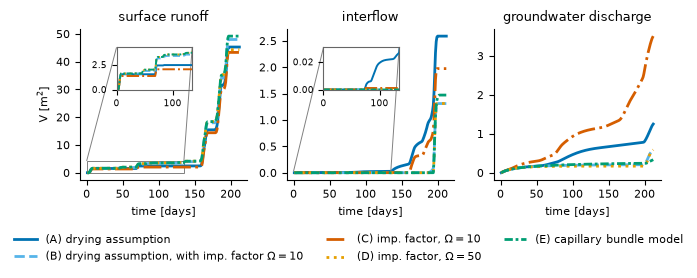

In [11]:
fig, axes = plotting_utils.plot_cumulative_partitioning_grid_with_inset(era5_dbs)
fig.savefig(f"../../figures/results/simulation/sim_cum.png", dpi=600)

### Temperature distribution     

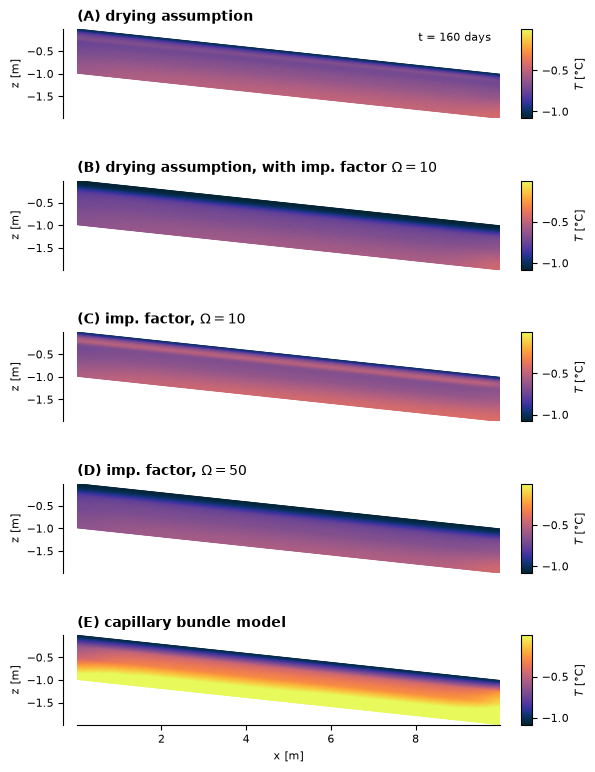

In [13]:
index = 160
fig, axes = plotting_utils.plot_T_grid(era5_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../../figures/results/simulation/sim_{index}d_T.png",dpi=600)